# 02 - San Diego: attacking
1. Formation
2. Shot map and chances
3. Goal kicks and build-up
4. Long passes
5. Key threats

## Setup

In [1]:
import ast
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from mplsoccer import VerticalPitch

pd.set_option("display.max_columns", 50)

In [2]:
PROCESSED_FOLDER = Path("../../data/processed")
FIGURES_FOLDER = Path("../../figures")
FIGURES_FOLDER.mkdir(exist_ok=True)

# colours
SD_COLOR = "#2a78d6"          # San Diego = blue
BACKGROUND = "#fcfcfb"
LINE_COLOR = "#9a9890"        # pitch lines, light grey so the data stands out
TEXT_COLOR = "#0b0b0b"
TEXT_MUTED = "#52514e"

# short names for charts
SHORT_NAMES = {
    "Hirving Rodrigo Lozano Bahena": "Chucky Lozano",
    "Anders Laustrup Dreyer": "Anders Dreyer",
    "Onni Johannes Simonpoika Valakari": "Onni Valakari",
    "Tomas Ángel Gutiérrez": "Tomás Ángel",
    "Alexander Cole Mighten": "Alex Mighten",
    "Jeppe Theis Tverskov": "Jeppe Tverskov",
    "Marcus Højriis Ingvartsen": "Marcus Ingvartsen",
    "Christopher Donald McVey": "Chris McVey",
    "Patrick James Coleman McNair": "Paddy McNair",
    "Aníbal Cesis Godoy": "Aníbal Godoy",
    "Carlos Joaquim Dos Santos": "CJ Dos Santos",
    "Luca Dylan Bombino": "Luca Bombino",
    "Oscar Anthony Verhoeven": "Oscar Verhoeven",
}

In [3]:
events = pd.read_parquet(PROCESSED_FOLDER / "sb_events.parquet")
matches = pd.read_parquet(PROCESSED_FOLDER / "matches.parquet")

sd_match_events = events[events["focus_team"] == "San Diego"]
is_sd_action = sd_match_events["team"] == "San Diego FC"
sd_own_events = sd_match_events[is_sd_action]
opponent_events_vs_sd = sd_match_events[~is_sd_action]

number_of_matches = sd_match_events["match_id"].nunique()
print("San Diego matches:", number_of_matches)

San Diego matches: 24


## 1 - Formation
From the Starting XI events (formation and players, stored as text).

In [4]:
starting_xi_rows = sd_own_events[sd_own_events["type"] == "Starting XI"]
example_text = starting_xi_rows["tactics"].iloc[0]
example_text[:300]

"{'formation': 433, 'lineup': [{'player': {'id': 132979, 'name': 'Carlos Joaquim Dos Santos'}, 'position': {'id': 1, 'name': 'Goalkeeper'}, 'jersey_number': 1}, {'player': {'id': 206469, 'name': 'Jasper Löffelsend'}, 'position': {'id': 2, 'name': 'Right Back'}, 'jersey_number': 19}, {'player': {'id':"

In [5]:
example_tactics = ast.literal_eval(example_text)
print("Keys:", example_tactics.keys())
print("Formation:", example_tactics["formation"])
print("First player:", example_tactics["lineup"][0])

Keys: dict_keys(['formation', 'lineup'])
Formation: 433
First player: {'player': {'id': 132979, 'name': 'Carlos Joaquim Dos Santos'}, 'position': {'id': 1, 'name': 'Goalkeeper'}, 'jersey_number': 1}


One row per player per match

In [6]:
lineup_rows = []

for index, row in starting_xi_rows.iterrows():
    tactics = ast.literal_eval(row["tactics"])
    formation = tactics["formation"]

    for slot in tactics["lineup"]:
        lineup_rows.append({
            "match_id": row["match_id"],
            "formation": formation,
            "player": slot["player"]["name"],
            "position": slot["position"]["name"],
        })

sd_lineups = pd.DataFrame(lineup_rows)
sd_lineups.head(11)

,match_id,formation,player,position
0,3981153,433,Carlos Joaquim Dos Santos,Goalkeeper
1,3981153,433,Jasper Löffelsend,Right Back
2,3981153,433,Christopher Donald McVey,Right Center Back
3,3981153,433,Patrick James Coleman McNair,Left Center Back
4,3981153,433,Franco Negri,Left Back
5,3981153,433,Jeppe Theis Tverskov,Center Defensive Midfield
6,3981153,433,Aníbal Cesis Godoy,Right Center Midfield
7,3981153,433,Luca de la Torre,Left Center Midfield
8,3981153,433,Anders Laustrup Dreyer,Right Wing
9,3981153,433,Hirving Rodrigo Lozano Bahena,Left Wing


In [7]:
formation_per_match = sd_lineups.drop_duplicates("match_id")
formation_per_match["formation"].value_counts()

formation
433      19
41212     4
442       1
Name: count, dtype: int64

4-3-3 in 19 of 24 games.

## 2 - Shot map and chances
Size = xG, filled = goal. Penalties removed.

In [8]:
sd_shots = sd_own_events[sd_own_events["type"] == "Shot"]
sd_shots_no_penalties = sd_shots[sd_shots["shot_type"] != "Penalty"]

is_goal = sd_shots_no_penalties["shot_outcome"] == "Goal"
sd_goals = sd_shots_no_penalties[is_goal]
sd_misses = sd_shots_no_penalties[~is_goal]

print("Shots (no penalties):", len(sd_shots_no_penalties), "| Goals:", len(sd_goals))

Shots (no penalties): 327 | Goals: 43


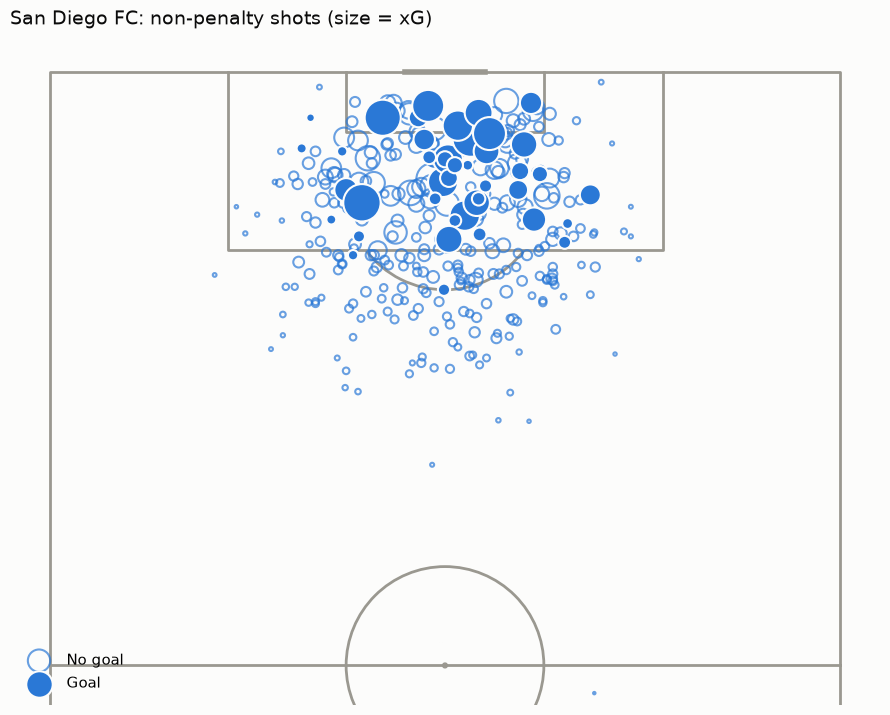

In [9]:
half_pitch = VerticalPitch(pitch_type="statsbomb", half=True, pitch_color=BACKGROUND, line_color=LINE_COLOR)
fig, ax = half_pitch.draw(figsize=(9, 8))
fig.set_facecolor(BACKGROUND)

half_pitch.scatter(sd_misses["x"], sd_misses["y"], s=sd_misses["shot_statsbomb_xg"] * 900,
                   facecolor="none", edgecolor=SD_COLOR, linewidth=1.5, alpha=0.7, ax=ax, label="No goal")
half_pitch.scatter(sd_goals["x"], sd_goals["y"], s=sd_goals["shot_statsbomb_xg"] * 900,
                   facecolor=SD_COLOR, edgecolor=BACKGROUND, linewidth=1.5, ax=ax, label="Goal")

ax.legend(loc="lower left", frameon=False, fontsize=11)
ax.set_title("San Diego FC: non-penalty shots (size = xG)", fontsize=14, color=TEXT_COLOR, loc="left")

fig.savefig(FIGURES_FOLDER / "ex1_sd_shot_map.png", dpi=200, bbox_inches="tight")
plt.show()

### How the chances are created
Each shot linked to its key pass. Set piece = possession from a corner or free kick. Box: x ≥ 102, 18 ≤ y ≤ 62.

In [10]:
key_passes = sd_own_events[sd_own_events["type"] == "Pass"]
key_passes = key_passes[["id", "pass_cross", "pass_cut_back", "pass_through_ball", "player"]]
key_passes = key_passes.rename(columns={"id": "shot_key_pass_id", "player": "passer"})

shot_columns = ["shot_key_pass_id", "play_pattern", "x", "y", "shot_body_part", "shot_outcome", "shot_statsbomb_xg", "player"]
chance_shots = sd_shots_no_penalties[shot_columns].merge(key_passes, on="shot_key_pass_id", how="left")


def chance_type(row):
    if row["play_pattern"] in ["From Corner", "From Free Kick"]:
        return "Set piece"
    elif row["pass_cross"] == True:
        return "Cross"
    elif row["pass_cut_back"] == True:
        return "Cutback"
    elif row["pass_through_ball"] == True:
        return "Through ball"
    elif pd.isna(row["shot_key_pass_id"]):
        return "No pass (dribble, rebound)"
    else:
        return "Short pass around the box"


chance_shots["chance_type"] = chance_shots.apply(chance_type, axis=1)
chance_shots["goal"] = chance_shots["shot_outcome"] == "Goal"
chance_shots["header"] = chance_shots["shot_body_part"] == "Head"
chance_shots["in_box"] = (chance_shots["x"] >= 102) & (chance_shots["y"] >= 18) & (chance_shots["y"] <= 62)

In [11]:
by_chance = chance_shots.groupby("chance_type").agg(
    shots=("goal", "size"), goals=("goal", "sum"), xG=("shot_statsbomb_xg", "sum"), headers=("header", "sum"))
by_chance["% of npxG"] = by_chance["xG"] / by_chance["xG"].sum() * 100
by_chance = by_chance.sort_values("xG", ascending=False)
by_chance.round(1)

,shots,goals,xG,headers,% of npxG
chance_type,,,,,
Short pass around the box,132,15,11.1,2,33.1
Set piece,110,9,9.7,26,28.9
Cross,27,6,4.6,10,13.8
Through ball,15,8,4.1,0,12.1
"No pass (dribble, rebound)",40,5,3.9,2,11.6
Cutback,3,0,0.2,0,0.5


In [12]:
# inside vs outside the box
by_area = chance_shots.groupby("in_box").agg(shots=("goal", "size"), goals=("goal", "sum"), xG=("shot_statsbomb_xg", "sum"))
by_area.round(1)

,shots,goals,xG
in_box,,,
False,130,3,5.3
True,197,40,28.4


In [13]:
# who plays the through balls and the crosses
through_balls = chance_shots[chance_shots["chance_type"] == "Through ball"]
crosses = chance_shots[chance_shots["chance_type"] == "Cross"]
print("Through balls:", through_balls["passer"].value_counts().head(3).to_dict())
print("Crosses:", crosses["passer"].value_counts().head(3).to_dict())

Through balls: {'Anders Laustrup Dreyer': 4, 'Onni Johannes Simonpoika Valakari': 3, 'Jeppe Theis Tverskov': 2}
Crosses: {'Anders Laustrup Dreyer': 6, 'Luca Dylan Bombino': 5, 'Oscar Anthony Verhoeven': 4}


40 of 43 non-penalty goals come from inside the box (3 from 130 shots outside). Through balls: 8 goals from 15 shots, mostly from Dreyer and Valakari. Set pieces 29% of their non-penalty xG, crosses 14%.

## 3 - Goal kicks and build-up
Short = ends in San Diego's own third (end x ≤ 40).

In [14]:
is_goal_kick = (sd_own_events["type"] == "Pass") & (sd_own_events["pass_type"] == "Goal Kick")
sd_goal_kicks = sd_own_events[is_goal_kick].copy()

sd_goal_kicks["short"] = sd_goal_kicks["end_x"] <= 40
short_share = sd_goal_kicks["short"].mean()

print("Goal kicks:", len(sd_goal_kicks))
print(f"Played short: {short_share:.0%}")

Goal kicks: 136
Played short: 78%


### After a short goal kick
For each possession: furthest point reached, reached the middle third (x > 40), the final third (x > 80), ended in a shot.

In [15]:
short_kicks = sd_goal_kicks[sd_goal_kicks["short"]]

# one row per possession
short_kick_possessions = short_kicks[["match_id", "possession"]].drop_duplicates()
print("Possessions starting with a short goal kick:", len(short_kick_possessions))

Possessions starting with a short goal kick: 106


In [16]:
# SD events in those possessions
events_after_short_kicks = sd_own_events.merge(short_kick_possessions, on=["match_id", "possession"])
events_after_short_kicks[["match_id", "possession", "type", "player", "x", "y"]].head(10)

,match_id,possession,type,player,x,y
0,3981153,67,Pass,Patrick James Coleman McNair,6.0,31.0
1,3981153,67,Pass,Carlos Joaquim Dos Santos,7.5,40.4
2,3981153,67,Pass,Aníbal Cesis Godoy,16.8,41.6
3,3981153,67,Pass,Patrick James Coleman McNair,7.1,22.7
4,3981153,67,Pass,Franco Negri,34.7,1.6
5,3981153,67,Pass,Luca de la Torre,77.1,4.0
6,3981153,67,Pass,Hirving Rodrigo Lozano Bahena,88.5,18.7
7,3981153,139,Pass,Patrick James Coleman McNair,7.0,32.9
8,3981153,139,Pass,Carlos Joaquim Dos Santos,5.1,41.4
9,3981153,139,Pass,Patrick James Coleman McNair,3.8,22.0


In [17]:
# furthest x per possession
furthest_x = events_after_short_kicks.groupby(["match_id", "possession"])["x"].max()
furthest_x.head()

match_id  possession
3981153   67            97.7
          139           51.1
          153           51.9
3981172   63            51.1
          69            12.8
Name: x, dtype: float64

In [18]:
reached_middle_third = furthest_x > 40
reached_final_third = furthest_x > 80
print(f"Short goal kicks that reach the middle third: {reached_middle_third.mean():.0%}")
print(f"Short goal kicks that reach the final third:  {reached_final_third.mean():.0%}")

Short goal kicks that reach the middle third: 79%
Short goal kicks that reach the final third:  45%


In [19]:
# ended in a shot, and xG
shots_after_short_kicks = events_after_short_kicks[events_after_short_kicks["type"] == "Shot"]

possessions_with_shot = shots_after_short_kicks[["match_id", "possession"]].drop_duplicates()
xg_after_short_kicks = shots_after_short_kicks["shot_statsbomb_xg"].sum()

print("Possessions ending in a shot:", len(possessions_with_shot), "of", len(short_kick_possessions))
print(f"Total xG from them: {xg_after_short_kicks:.2f}")

Possessions ending in a shot: 10 of 106
Total xG from them: 1.62


In [20]:
funnel = pd.Series({
    "Goal kicks": len(sd_goal_kicks),
    "Played short": len(short_kick_possessions),
    "Reach the middle third": reached_middle_third.sum(),
    "Reach the final third": reached_final_third.sum(),
    "End in a shot": len(possessions_with_shot),
})
funnel


Goal kicks                136
Played short              106
Reach the middle third     84
Reach the final third      48
End in a shot              10
dtype: int64

Of the 106 short goal kicks, 79% reach the middle third, 45% the final third and 9% end in a shot.

### Possession
Share of match time with the ball. Each possession lasts until the next one starts (capped at 3 minutes for stoppages).

In [21]:
events_sorted = events.sort_values(["match_id", "index"]).copy()
events_sorted["seconds"] = events_sorted["minute"] * 60 + events_sorted["second"]

possession_table = events_sorted.groupby(["match_id", "possession"]).agg(
    focus_team=("focus_team", "first"),
    team=("possession_team", "first"),
    period=("period", "first"),
    start=("seconds", "min"),
).reset_index()
possession_table["end"] = possession_table.groupby(["match_id", "period"])["start"].shift(-1)
possession_table = possession_table.dropna(subset=["end"])
possession_table["duration"] = (possession_table["end"] - possession_table["start"]).clip(lower=0, upper=180)


def possession_share(focus_team, team_name):
    rows = possession_table[possession_table["focus_team"] == focus_team]
    seconds_per_team = rows.groupby(["match_id", "team"])["duration"].sum().unstack()
    return seconds_per_team[team_name] / seconds_per_team.sum(axis=1) * 100


sd_possession = possession_share("San Diego", "San Diego FC")
nashville_possession = possession_share("Nashville", "Nashville SC")
print(f"San Diego possession: {sd_possession.mean():.0f}% on average, more than half the ball in {(sd_possession > 50).sum()} of {len(sd_possession)} games")
print(f"Nashville possession: {nashville_possession.mean():.0f}% on average")


San Diego possession: 57% on average, more than half the ball in 21 of 24 games
Nashville possession: 51% on average


57% possession on average, more than half the ball in 21 of 24 games.

### Build-up lanes: all possessions
First carry or completed pass from the own third into the middle third, one per possession. San Diego, Nashville and the opponents of both.
y = 0 is the attacking team's left.

In [22]:
def get_lane(y):
    if y < 80 / 3:
        return "Left"
    elif y < 2 * 80 / 3:
        return "Centre"
    else:
        return "Right"


def first_moves_into_middle(team_events):
    # only the team's own possessions
    team_events = team_events[team_events["possession_team"] == team_events["team"]]
    in_order = team_events.sort_values(["match_id", "index"])

    starts_in_own_third = in_order["x"] <= 40
    ends_in_middle_third = in_order["end_x"] > 40
    is_carry = in_order["type"] == "Carry"
    is_completed_pass = (in_order["type"] == "Pass") & in_order["pass_outcome"].isna()

    moves = in_order[starts_in_own_third & ends_in_middle_third & (is_carry | is_completed_pass)]
    first_moves = moves.drop_duplicates(["match_id", "possession"]).copy()
    first_moves["lane"] = first_moves["end_y"].apply(get_lane)
    return first_moves

In [23]:
nashville_match_events = events[events["focus_team"] == "Nashville"]
is_nashville_action = nashville_match_events["team"] == "Nashville SC"

build_ups = {
    "San Diego": first_moves_into_middle(sd_own_events),
    "Nashville": first_moves_into_middle(nashville_match_events[is_nashville_action]),
    "Opponents vs San Diego": first_moves_into_middle(opponent_events_vs_sd),
    "Opponents vs Nashville": first_moves_into_middle(nashville_match_events[~is_nashville_action]),
}

lane_rows = []
for team, moves in build_ups.items():
    shares = moves["lane"].value_counts(normalize=True) * 100
    lane_rows.append({
        "team": team,
        "Left": shares["Left"],
        "Centre": shares["Centre"],
        "Right": shares["Right"],
        "build-ups": len(moves),
    })

lane_table = pd.DataFrame(lane_rows).set_index("team")
lane_table.round(0)

,Left,Centre,Right,build-ups
team,,,,
San Diego,37.0,31.0,32.0,967
Nashville,38.0,22.0,40.0,902
Opponents vs San Diego,36.0,26.0,38.0,826
Opponents vs Nashville,39.0,23.0,38.0,885


31% of San Diego's build-ups go through the centre, against 22% for Nashville and 23-26% for the opponents.

## 4 - Long passes
Open-play passes only (no corners, free kicks, throw-ins, goal kicks, kick-offs). Long = 32+ yards (about 30 m).

In [24]:
set_piece_passes = ["Corner", "Free Kick", "Throw-in", "Goal Kick", "Kick Off"]

is_pass = sd_own_events["type"] == "Pass"
is_open_play = ~sd_own_events["pass_type"].isin(set_piece_passes)
sd_open_play_passes = sd_own_events[is_pass & is_open_play].copy()

sd_open_play_passes["long"] = sd_open_play_passes["pass_length"] >= 32
sd_open_play_passes["completed"] = sd_open_play_passes["pass_outcome"].isna()

In [25]:
# who plays the long passes
sd_long_passes = sd_open_play_passes[sd_open_play_passes["long"]]

long_passers = sd_long_passes.groupby("player").agg(long_passes=("long", "size"), completion=("completed", "mean"))
long_passers = long_passers.sort_values("long_passes", ascending=False)
long_passers.head(5).round(2)

,long_passes,completion
player,,
Christopher Donald McVey,228,0.75
Patrick James Coleman McNair,205,0.76
Jeppe Theis Tverskov,189,0.70
Aníbal Cesis Godoy,118,0.73
Anders Laustrup Dreyer,94,0.53


Long passes mostly come from McVey (228), McNair (205) and Tverskov (189), 70-76% completed.

## 5 - Key threats
- npxG: non-penalty xG
- xA: xG of the shot each pass created

In [26]:
# finishing: npxG per player
npxg_per_player = sd_shots_no_penalties.groupby("player")["shot_statsbomb_xg"].sum()
goals_per_player = sd_goals.groupby("player").size()

In [27]:
# xA: the passer gets the xG of the shot
shots_with_key_pass = sd_shots_no_penalties.dropna(subset=["shot_key_pass_id"])
shots_with_key_pass = shots_with_key_pass[["shot_key_pass_id", "shot_statsbomb_xg"]]

passes = sd_own_events[sd_own_events["type"] == "Pass"]
passers = passes[["id", "player"]]

key_passes = shots_with_key_pass.merge(passers, left_on="shot_key_pass_id", right_on="id")
xa_per_player = key_passes.groupby("player")["shot_statsbomb_xg"].sum()
key_passes.head()

,shot_key_pass_id,shot_statsbomb_xg,id,player
0,c383e576-6016-5a55-9945-68fd8d5b780c,0.010330,c383e576-6016-5a55-9945-68fd8d5b780c,Luca de la Torre
1,a2dc276e-774e-5ad2-809c-cb1f85109260,0.518173,a2dc276e-774e-5ad2-809c-cb1f85109260,Hirving Rodrigo Lozano Bahena
2,ddd76d9e-45c0-545b-9ee2-f1f8f29b6432,0.059613,ddd76d9e-45c0-545b-9ee2-f1f8f29b6432,Anders Laustrup Dreyer
3,e2fa90a7-9b5a-5c5e-ac8a-56e546da8385,0.226715,e2fa90a7-9b5a-5c5e-ac8a-56e546da8385,Franco Negri
4,40b98f54-b6aa-5e38-a043-76dea5b03831,0.029431,40b98f54-b6aa-5e38-a043-76dea5b03831,Onni Johannes Simonpoika Valakari


Approximate minutes: first to last event in each match (starters from 0)

In [28]:
player_events = sd_own_events.dropna(subset=["player"])

first_minute = player_events.groupby(["match_id", "player"])["minute"].min()
last_minute = player_events.groupby(["match_id", "player"])["minute"].max()

player_minutes = pd.DataFrame({"first": first_minute, "last": last_minute}).reset_index()

# starters start at minute 0
starter_keys = sd_lineups[["match_id", "player"]].copy()
starter_keys["started"] = True
player_minutes = player_minutes.merge(starter_keys, on=["match_id", "player"], how="left")
player_minutes["started"] = player_minutes["started"].fillna(False)
player_minutes.loc[player_minutes["started"], "first"] = 0

player_minutes["minutes"] = player_minutes["last"] - player_minutes["first"]
minutes_per_player = player_minutes.groupby("player")["minutes"].sum()

In [29]:
threats = pd.DataFrame({
    "minutes": minutes_per_player,
    "goals": goals_per_player,
    "npxG": npxg_per_player,
    "xA": xa_per_player,
})
threats = threats.fillna(0)

threats["npxG per 90"] = threats["npxG"] / threats["minutes"] * 90
threats["xA per 90"] = threats["xA"] / threats["minutes"] * 90
threats["npxG+xA per 90"] = threats["npxG per 90"] + threats["xA per 90"]

# at least 450 minutes
regular_players = threats[threats["minutes"] >= 450]
regular_players = regular_players.sort_values("npxG+xA per 90", ascending=False)
regular_players.head(10).round(2)

,minutes,goals,npxG,xA,npxG per 90,xA per 90,npxG+xA per 90
player,,,,,,,
Milan Iloski,527,10.0,4.23,0.82,0.72,0.14,0.86
Hirving Rodrigo Lozano Bahena,1297,4.0,5.86,2.92,0.41,0.20,0.61
Anders Laustrup Dreyer,2236,9.0,7.37,7.57,0.30,0.30,0.60
Onni Johannes Simonpoika Valakari,1663,4.0,3.50,2.53,0.19,0.14,0.33
Tomas Ángel Gutiérrez,645,3.0,1.46,0.77,0.20,0.11,0.31
Alexander Cole Mighten,949,1.0,2.01,0.78,0.19,0.07,0.26
Jasper Löffelsend,625,0.0,0.23,1.29,0.03,0.19,0.22
Jeppe Theis Tverskov,2163,1.0,1.14,3.16,0.05,0.13,0.18
Luca de la Torre,1616,4.0,1.44,1.35,0.08,0.07,0.16


Top 8: npxG + xA per 90

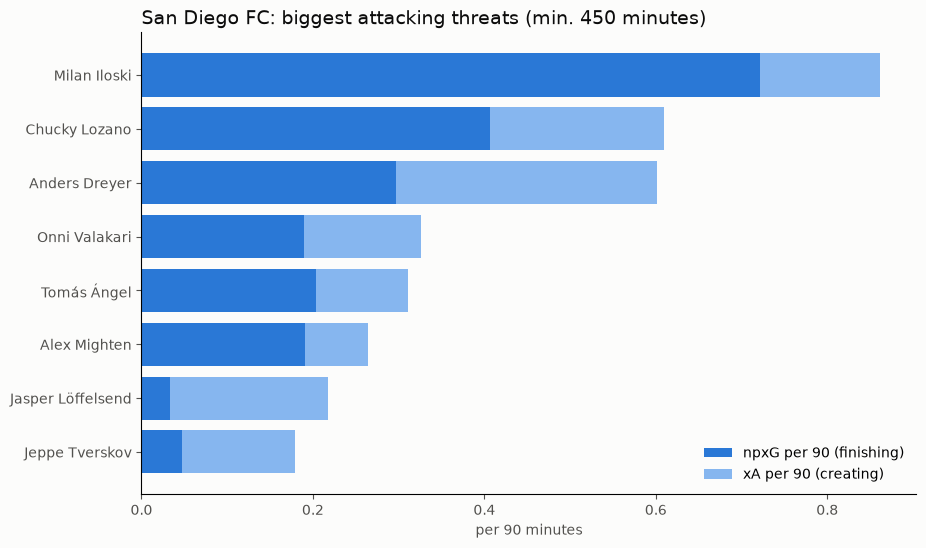

In [30]:
top_threats = regular_players.head(8)
top_threats = top_threats.sort_values("npxG+xA per 90")       # biggest bar at the top
top_threats = top_threats.rename(index=SHORT_NAMES)

fig, ax = plt.subplots(figsize=(10, 6))
fig.set_facecolor(BACKGROUND)
ax.set_facecolor(BACKGROUND)

ax.barh(top_threats.index, top_threats["npxG per 90"], color=SD_COLOR, label="npxG per 90 (finishing)")
ax.barh(top_threats.index, top_threats["xA per 90"], left=top_threats["npxG per 90"],
        color="#86b6ef", label="xA per 90 (creating)")

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
ax.tick_params(colors=TEXT_MUTED)
ax.set_xlabel("per 90 minutes", color=TEXT_MUTED)
ax.legend(frameon=False, loc="lower right")
ax.set_title("San Diego FC: biggest attacking threats (min. 450 minutes)", fontsize=14, color=TEXT_COLOR, loc="left")

fig.savefig(FIGURES_FOLDER / "ex1_sd_threats.png", dpi=200, bbox_inches="tight")
plt.show()